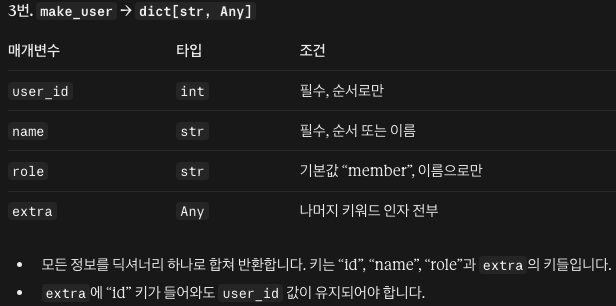

In [1]:
from typing import Any
from collections.abc import Callable

In [2]:
def make_user(user_id: int, / , name: str , * , role: str = "member", **extra : Any) -> dict[str, Any]:
    # 키는 str, 밸류는 Any
    
    keys_ = ["id","name","role"]
    keys_.extend(list(extra.keys()))

    values_ = [user_id, name, role]
    values_.extend(list(extra.values()))

    result_dict = dict(zip(keys_, values_))
    
    result_dict["id"] = user_id

    return result_dict

In [3]:
# 더 짧게

def make_user(user_id: int, / , name: str , * , role: str = "member", **extra : Any) -> dict[str, Any]:
    return {**extra, "id": user_id, "name": name, "role": role}

"작성하면 바로 호출해 본다"는 습관이 문법 지식보다 버그를 더 많이 잡아 줍니다.

In [4]:
print(make_user(1,"철수"))
print(make_user(1,"철수", role = "admin", city = "광주", id = 999))

{'id': 1, 'name': '철수', 'role': 'member'}
{'city': '광주', 'id': 1, 'name': '철수', 'role': 'admin'}


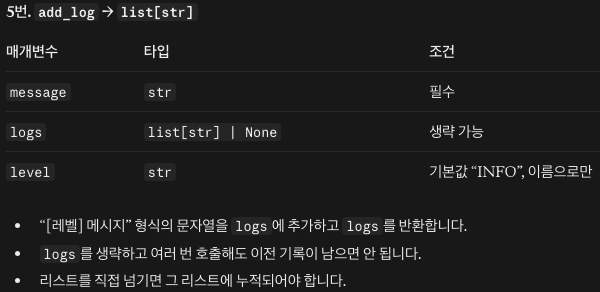

In [5]:
def add_log( message: str, logs: list[str]|None = None, * , level: str = "INFO") -> list[str]:

    if logs is None: # None 비교는 is None 이 관례
        logs = []
    logs.append(f"[{level}] {message}")
    
    return logs

In [6]:
print(add_log("hello world", ['a','b','c'], level = 'info'))
print(add_log("hi"))

['a', 'b', 'c', '[info] hello world']
['[INFO] hi']


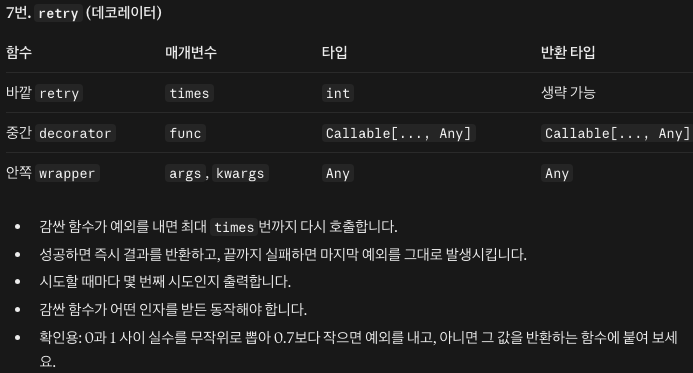

In [7]:
import random
from functools import wraps

def retry( times: int ):
    def decorator( func: Callable[..., Any]) -> Callable[..., Any]:
        @wraps(func)
        def wrapper(*args, **kwargs):
            for attempt in range(1, times+1):
                print(f"{attempt}번째 시도입니다.")
                print()
                try:
                    return func(*args, **kwargs)
                except Exception:
                    if attempt == times:
                        raise
        return wrapper
    return decorator

In [8]:
@retry(5)
def test():
    f = random.uniform(0,1)
    if f > 0.7:
        return f
    else:
        raise ValueError(f"실패: {f:.2f}") # 출력하는게 아니라, 에러메시지에 포함되는 내용
print(test())

1번째 시도입니다.

0.7361157619831554
